# Module 02: Vectors and Geometry

A vector is at once an **arrow** (a direction and a length), a **list of numbers** (a row of your dataset), and a
**point** in space. ML switches between these views constantly. A data point is a list of numbers, a similarity is
an angle between arrows, and a nearest neighbor is a distance between points.

**Learning goals**
- Add and scale vectors, and picture both
- Linear combinations and span
- The dot product: as algebra, as an angle, and as a projection
- L1, L2 and L∞ norms and distances
- Cosine similarity for embeddings
- Orthogonality

In [1]:
# Standard setup: make the repo root importable, load the usual tools, fix the random seed.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # notebooks live in modules/XX_name/, so go up two levels
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from common.checks import check
from common import plotting as mplt

sp.init_printing()                         # pretty-print SymPy results as math
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)            # use rng.normal(...), rng.integers(...) for reproducible randomness

## 1. Vectors: arrows, lists and points
$\mathbf{v} = \begin{pmatrix} 3 \\ 1 \end{pmatrix} \in \mathbb{R}^2$ is "go 3 right and 1 up". In NumPy it is
just `np.array([3, 1])`. A house with features (area, rooms, age) is a vector in $\mathbb{R}^3$, and an image with
784 pixels is a vector in $\mathbb{R}^{784}$. The geometry works the same in every dimension. We draw 2-D because
we can.

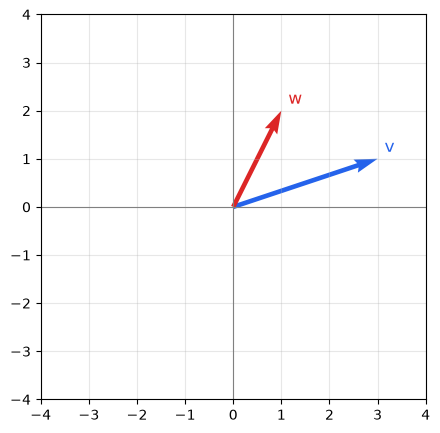

In [2]:
v = np.array([3.0, 1.0])
w = np.array([1.0, 2.0])
mplt.plot_vectors([v, w], labels=["v", "w"])
plt.show()

## 2. Addition and scaling
- **Addition** $\mathbf{v} + \mathbf{w}$ is component-wise. Geometrically, put w's tail at v's head (tip to tail).
- **Scaling** $c\mathbf{v}$ stretches by c. A negative c flips the direction.

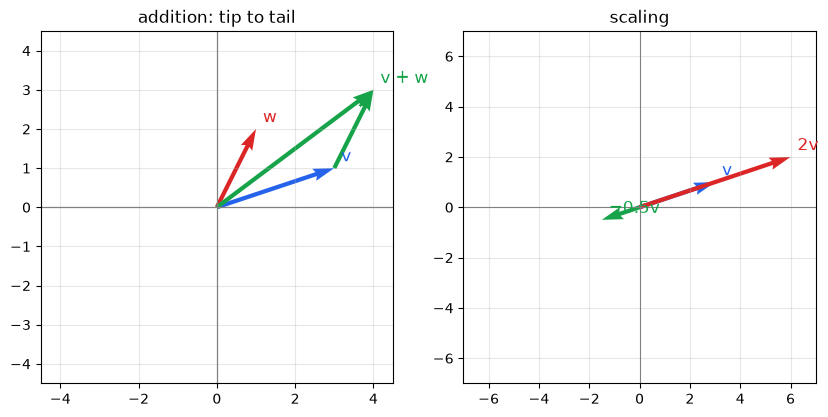

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
mplt.plot_vectors([v, w, v + w], labels=["v", "w", "v + w"], ax=axs[0], title="addition: tip to tail")
mplt.plot_vectors([w], origin=v, ax=axs[0], colors=["#16a34a"], lim=4.5)    # w drawn starting at v's tip
mplt.plot_vectors([v, 2 * v, -0.5 * v], labels=["v", "2v", "−0.5v"], ax=axs[1], title="scaling", lim=7)
plt.show()

## 3. Linear combinations and span
A **linear combination** of v and w is $a\mathbf{v} + b\mathbf{w}$ for any scalars a, b. The **span** is the set of
all of them.
- Two vectors pointing in different directions in 2-D: the span is **the whole plane**.
- Two vectors on the same line (one is a multiple of the other): the span is **just that line**.

A linear model's prediction $\hat{y} = w_1 x_1 + w_2 x_2 + \dots$ is a linear combination. So is
"a matrix times a vector" (module 03).

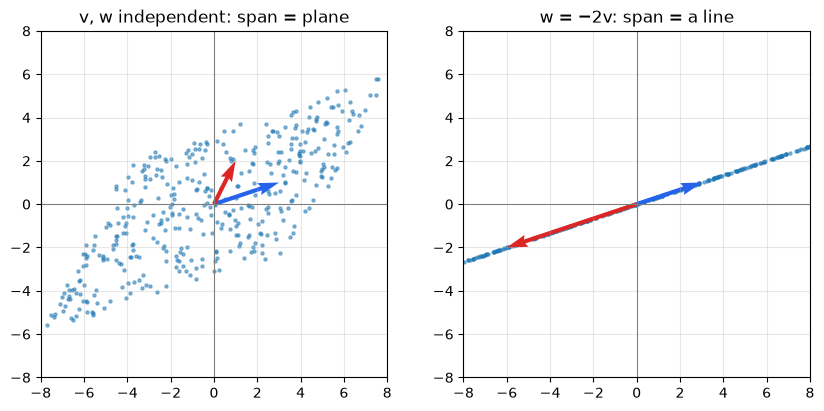

In [4]:
coeffs = rng.uniform(-2, 2, size=(400, 2))
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (a_vec, b_vec, title) in zip(axs, [(v, w, "v, w independent: span = plane"),
                                          (v, -2 * v, "w = −2v: span = a line")]):
    pts = coeffs[:, :1] * a_vec + coeffs[:, 1:] * b_vec       # 400 random combinations a*v + b*w
    ax.scatter(pts[:, 0], pts[:, 1], s=5, alpha=0.5)
    mplt.plot_vectors([a_vec, b_vec], ax=ax, lim=8, title=title)
plt.show()

## 4. The dot product
**Algebra:** multiply matching components and add them up:
$$\mathbf{v} \cdot \mathbf{w} = \mathbf{v}^\top\mathbf{w} = \sum_{i=1}^n v_i w_i.$$
**Geometry:** the same number equals
$$\mathbf{v} \cdot \mathbf{w} = \lVert\mathbf{v}\rVert\,\lVert\mathbf{w}\rVert \cos\theta,$$
where θ is the angle between them. So the sign tells you about the direction:

| dot product | angle | meaning |
|---|---|---|
| > 0 | < 90° | pointing roughly the same way |
| = 0 | = 90° | **orthogonal** (perpendicular) |
| < 0 | > 90° | pointing roughly opposite ways |

In [5]:
print("v·w =", v @ w, "=", np.dot(v, w), "=", np.sum(v * w))    # three ways to write it
cos_theta = (v @ w) / (np.linalg.norm(v) * np.linalg.norm(w))
print("angle between v and w:", np.degrees(np.arccos(cos_theta)), "degrees")

v·w = 5.0 = 5.0 = 5.0
angle between v and w: 45.00000000000001 degrees


### Projection: the dot product as a "shadow"
The projection of w onto the direction of v is the shadow w casts on the line through v:
$$\text{proj}_{\mathbf{v}}\mathbf{w} = \frac{\mathbf{v}\cdot\mathbf{w}}{\mathbf{v}\cdot\mathbf{v}}\,\mathbf{v}.$$
The leftover piece $\mathbf{w} - \text{proj}_{\mathbf{v}}\mathbf{w}$ is **orthogonal** to v. Projections drive
least squares (module 05) and PCA (module 07).

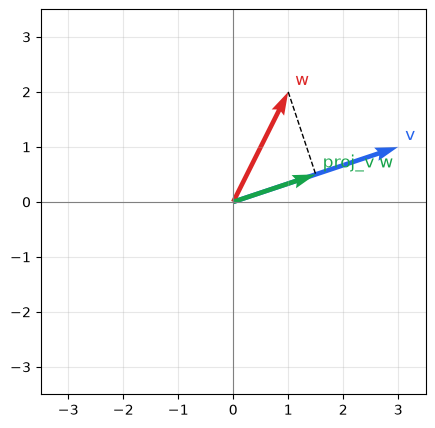

residual · v = 0.0 (orthogonal)


In [6]:
proj = (v @ w) / (v @ v) * v
residual = w - proj
ax = mplt.plot_vectors([v, w, proj], labels=["v", "w", "proj_v w"], lim=3.5)
ax.plot([w[0], proj[0]], [w[1], proj[1]], "k--", lw=1)
plt.show()
print("residual · v =", residual @ v, "(orthogonal)")

## 5. Norms: measuring length
| Norm | Formula | NumPy | In ML |
|---|---|---|---|
| L2 (Euclidean) | $\lVert\mathbf{x}\rVert_2 = \sqrt{\sum_i x_i^2}$ | `np.linalg.norm(x)` | distances, Ridge penalty, weight decay |
| L1 (Manhattan) | $\lVert\mathbf{x}\rVert_1 = \sum_i \lvert x_i\rvert$ | `np.linalg.norm(x, 1)` | Lasso penalty, MAE |
| L∞ (max) | $\lVert\mathbf{x}\rVert_\infty = \max_i \lvert x_i\rvert$ | `np.linalg.norm(x, np.inf)` | adversarial robustness |

Note $\lVert\mathbf{x}\rVert_2^2 = \mathbf{x}\cdot\mathbf{x}$. The **unit ball** (all x with norm ≤ 1) has a
different shape for each norm. The L1 ball's sharp corners are why Lasso produces exact zeros.

L2: 5.0  L1: 7.0  L∞: 4.0


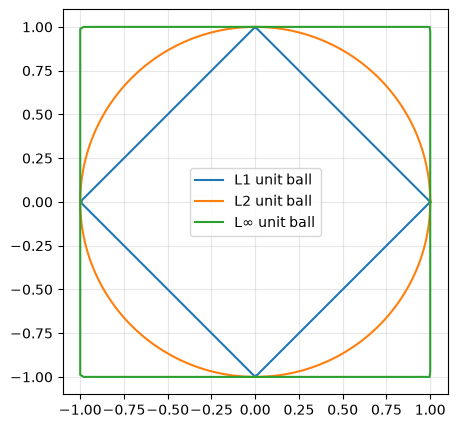

In [7]:
x = np.array([3.0, -4.0])
print("L2:", np.linalg.norm(x), " L1:", np.linalg.norm(x, 1), " L∞:", np.linalg.norm(x, np.inf))

theta = np.linspace(0, 2 * np.pi, 400)
dirs = np.stack([np.cos(theta), np.sin(theta)], axis=1)
fig, ax = plt.subplots(figsize=(5, 5))
for p, name in [(1, "L1"), (2, "L2"), (np.inf, "L∞")]:
    pts = dirs / np.linalg.norm(dirs, ord=p, axis=1, keepdims=True)   # rescale each direction to norm 1
    ax.plot(pts[:, 0], pts[:, 1], label=f"{name} unit ball")
ax.set_aspect("equal"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

### Unit vectors and distances
- **Normalizing** $\hat{\mathbf{x}} = \mathbf{x}/\lVert\mathbf{x}\rVert$ keeps the direction and sets the length to 1.
- **Distance** between points is the norm of their difference: $d(\mathbf{a}, \mathbf{b}) = \lVert\mathbf{a} - \mathbf{b}\rVert$.
  KNN and k-means are built on this.

In [8]:
a_pt, b_pt = np.array([1.0, 1.0]), np.array([4.0, 5.0])
print("unit x:", x / np.linalg.norm(x), "length", np.linalg.norm(x / np.linalg.norm(x)))
print("Euclidean distance:", np.linalg.norm(a_pt - b_pt), " Manhattan:", np.linalg.norm(a_pt - b_pt, 1))

unit x: [ 0.6 -0.8] length 1.0
Euclidean distance: 5.0  Manhattan: 7.0


### All pairwise distances at once (vectorized)
Using $\lVert\mathbf{a} - \mathbf{b}\rVert^2 = \lVert\mathbf{a}\rVert^2 - 2\,\mathbf{a}\cdot\mathbf{b} + \lVert\mathbf{b}\rVert^2$,
a whole distance matrix takes one matrix product. This is how fast KNN libraries work.

In [9]:
P = rng.normal(size=(5, 3))
sq = (P ** 2).sum(axis=1)
D2 = sq[:, None] - 2 * P @ P.T + sq[None, :]
D = np.sqrt(np.maximum(D2, 0))              # clip tiny negatives caused by rounding
from scipy.spatial.distance import cdist
print(np.allclose(D, cdist(P, P)))

True


## 6. Cosine similarity and embeddings
$$\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert} \in [-1, 1]$$
It ignores length and compares only direction. Embedding models (word2vec, sentence transformers, CLIP) place
similar things in similar directions, and retrieval systems rank by cosine similarity.

Here is a toy, hand-made 4-D "embedding". The dimensions are roughly (royalty, maleness, femaleness, fruitiness):

In [10]:
emb = {
    "king":   np.array([0.9, 0.8, 0.1, 0.0]),
    "queen":  np.array([0.9, 0.1, 0.8, 0.0]),
    "man":    np.array([0.1, 0.9, 0.1, 0.0]),
    "woman":  np.array([0.1, 0.1, 0.9, 0.0]),
    "apple":  np.array([0.0, 0.0, 0.1, 0.9]),
}

def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

for w2 in ["queen", "man", "apple"]:
    print(f"cos(king, {w2}) = {cosine(emb['king'], emb[w2]):.3f}")

target = emb["king"] - emb["man"] + emb["woman"]        # the famous analogy, as vector arithmetic
best = max((wd for wd in emb if wd not in {"king", "man", "woman"}), key=lambda wd: cosine(target, emb[wd]))
print("king − man + woman ≈", best)

cos(king, queen) = 0.664
cos(king, man) = 0.745
cos(king, apple) = 0.009
king − man + woman ≈ queen


## 7. Orthogonality
Vectors are **orthogonal** when their dot product is 0. Orthogonal directions carry **independent** information:
moving along one doesn't move you along the other. The standard basis $\mathbf{e}_1 = (1, 0)$, $\mathbf{e}_2 = (0, 1)$
is orthogonal, and so are the principal components found by PCA. In high dimensions, random vectors are
**almost orthogonal**, which is one reason embeddings with hundreds of dimensions can store so much.

In [11]:
for dim in [2, 10, 100, 1000]:
    A = rng.normal(size=(200, dim))
    An = A / np.linalg.norm(A, axis=1, keepdims=True)
    cos = An @ An.T
    off_diag = np.abs(cos[~np.eye(200, dtype=bool)])
    print(f"dim {dim:5d}: mean |cos| between random vectors = {off_diag.mean():.3f}")

dim     2: mean |cos| between random vectors = 0.635
dim    10: mean |cos| between random vectors = 0.258
dim   100: mean |cos| between random vectors = 0.079


dim  1000: mean |cos| between random vectors = 0.025


## Where you'll use this
- **ML course:** 07 linear regression (ŷ = w·x + b), 09 Ridge/Lasso (L2/L1 norms), 11 KNN and 15 k-means (distances).
- **DL course:** 01 MLP (each neuron is a dot product), 21 word embeddings and 28 retrieval (cosine similarity).

## Summary
- Vectors add tip to tail and scale by stretching. Linear combinations fill out their span.
- v·w = Σ vᵢwᵢ = ‖v‖‖w‖cos θ. Its sign tells you the direction, and 0 means orthogonal.
- proj_v w = (v·w / v·v) v, and the residual is orthogonal to v.
- The L1, L2 and L∞ norms measure length differently. Distance = norm of the difference.
- Cosine similarity compares direction only. It is the standard similarity for embeddings.

## 📚 Recommended videos, books and papers
⭐ = start here. The others are optional, for going deeper.

### 🎥 Videos
- ⭐ [Vectors (Essence of linear algebra, ch. 1)](https://www.3blue1brown.com/lessons/vectors) (3Blue1Brown). The three views of a vector: arrow, list of numbers, and abstract object.
- ⭐ [Dot products and duality (ch. 9)](https://www.3blue1brown.com/lessons/dot-products) (3Blue1Brown). Why the dot product is a projection.
- [Linear combinations, span, and basis vectors (ch. 2)](https://www.3blue1brown.com/lessons/span) (3Blue1Brown). Sets up modules 03–04.

### 📘 Books and articles
- [Mathematics for Machine Learning, ch. 3.1–3.4 (norms, inner products, angles)](https://mml-book.github.io/) (Deisenroth, Faisal & Ong, 2020). The standard ML math textbook. A free PDF.
- [Introduction to Applied Linear Algebra (VMLS), ch. 1–3](https://web.stanford.edu/~boyd/vmls/) (Boyd & Vandenberghe, 2018). Very applied and gentle, built around data vectors.

### 📄 Papers
Tip: read the abstract, the figures and the conclusion first, then the method section.

- [Efficient Estimation of Word Representations in Vector Space (word2vec)](https://arxiv.org/abs/1301.3781) (Mikolov et al., 2013). Where 'king − man + woman ≈ queen' and cosine similarity between word vectors became famous.